<a href="https://colab.research.google.com/github/Aahra/E-commerce-dataset/blob/main/Ecommerce.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import pandas as pd

order1 = "https://raw.githubusercontent.com/Aahra/E-commerce-dataset/main/Dataset/orders.csv"
order = pd.read_csv(order1, parse_dates=["order_date"])
print(order.shape)

(12480, 9)


In [35]:
display(order.head())

,order_id,customer_id,product_id,category,brand,price,quantity,order_date,city
0,ORD10001,CUST042,PRD017,Electronics,Boat,1299.0,1,2024-01-01,Mumbai
1,ORD10002,CUST119,PRD221,Fashion,Levis,2199.0,1,2024-01-01,Mumbai
2,ORD10003,CUST042,PRD088,Home & Kitchen,Milton,649.0,2,2024-01-02,Mumbai
3,ORD10004,CUST311,PRD500,Electronics,Samsung,18999.0,1,2024-01-02,Mumbai
4,ORD10005,CUST008,PRD156,Beauty,Lakme,399.0,3,2024-01-02,Bengaluru


In [36]:
print(pd.__version__)

2.2.3


In [37]:
customers ="https://raw.githubusercontent.com/Aahra/E-commerce-dataset/main/Dataset/customers.csv"
customer = pd.read_csv(customers,parse_dates=["signup_date"])
print(customer.shape)

(1500, 5)


In [38]:
products1="https://raw.githubusercontent.com/Aahra/E-commerce-dataset/main/Dataset/products.csv"
product= pd.read_csv(products1)
print(product.shape)

(600, 8)


In [39]:
order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12480 entries, 0 to 12479
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     12480 non-null  object        
 1   customer_id  12480 non-null  object        
 2   product_id   12480 non-null  object        
 3   category     12480 non-null  object        
 4   brand        12360 non-null  object        
 5   price        12480 non-null  float64       
 6   quantity     12480 non-null  int64         
 7   order_date   12480 non-null  datetime64[ns]
 8   city         12480 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 877.6+ KB


In [40]:
order[["price","quantity"]].describe()


,price,quantity
count,12480.000000,12480.000000
mean,1274.489744,1.663381
std,1728.344159,1.144670
min,149.000000,1.000000
25%,440.000000,1.000000
50%,776.000000,1.000000
75%,1555.000000,2.000000
max,18999.000000,8.000000


In [41]:
order[["category","city"]].describe()

,category,city
count,12480,12480
unique,6,8
top,Electronics,Mumbai
freq,4068,3048


In [42]:
order["city"].head(3)

,city
0,Mumbai
1,Mumbai
2,Mumbai


In [43]:
order[order["price"]>5000].head(5)

,order_id,customer_id,product_id,category,brand,price,quantity,order_date,city
3,ORD10004,CUST311,PRD500,Electronics,Samsung,18999.0,1,2024-01-02,Mumbai
71,ORD10044,CUST386,PRD500,Electronics,Samsung,18999.0,2,2024-01-04,Kolkata
355,ORD10227,CUST1471,PRD441,Electronics,Sony,8613.0,1,2024-01-08,Hyderabad
411,ORD10261,CUST1302,PRD567,Electronics,Realme,5695.0,1,2024-01-09,Bengaluru
437,ORD10278,CUST363,PRD500,Electronics,Samsung,18999.0,1,2024-01-09,Hyderabad


In [44]:
cols = order[["order_id","category","price","quantity","city"]]
cols.head(3)

,order_id,category,price,quantity,city
0,ORD10001,Electronics,1299.0,1,Mumbai
1,ORD10002,Fashion,2199.0,1,Mumbai
2,ORD10003,Home & Kitchen,649.0,2,Mumbai


In [45]:
order["revenue"]= order["price"] * order["quantity"]
order[["order_id","category","price","quantity","city","revenue"]].head(3)

,order_id,category,price,quantity,city,revenue
0,ORD10001,Electronics,1299.0,1,Mumbai,1299.0
1,ORD10002,Fashion,2199.0,1,Mumbai,2199.0
2,ORD10003,Home & Kitchen,649.0,2,Mumbai,1298.0


In [46]:
# High-value Electronics orders in Mumbai
mask = (order["city"] == "Mumbai") & (order["category"] == "Electronics") & (order["revenue"] > 2000)
order[mask][["order_id", "brand", "revenue"]].head()

,order_id,brand,revenue
3,ORD10004,Samsung,18999.0
12,ORD10009,Samsung,2013.0
44,ORD10029,Realme,5403.0
152,ORD10095,OnePlus,2160.0
192,ORD10120,OnePlus,4071.0


In [47]:
metro = order[order["city"].isin(["Mumbai", "Delhi", "Bengaluru"])]
print(len(metro), "line items in the three biggest metros")

7577 line items in the three biggest metros


In [48]:
by_category = (order.groupby("category")["revenue"].sum().sort_values(ascending=False))
print(by_category)

category
Electronics       9663403.0
Home & Kitchen    3496498.0
Fashion           3133305.0
Sports            3034279.0
Beauty            1129002.0
Books              771678.0
Name: revenue, dtype: float64


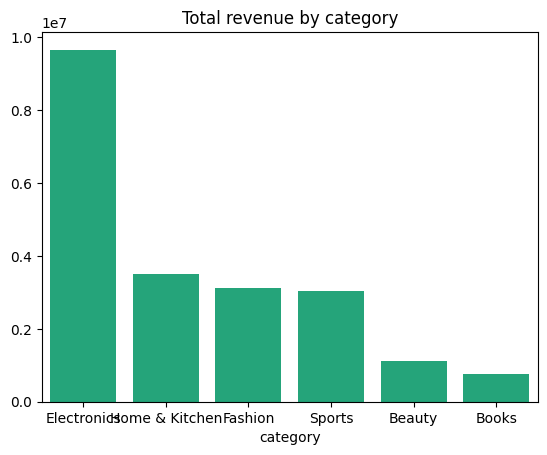

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.barplot(x=by_category.index, y=by_category.values,color="#10B981")
plt.title("Total revenue by category")
plt.show()

In [50]:
summary = order.groupby("category").agg(tot_rev=("revenue","sum"),uniq=("order_id", "nunique"),order_count = ("order_id","count"),avg_price=("price","mean"))
print(summary)

                  tot_rev  uniq  order_count    avg_price
category                                                 
Beauty          1129002.0  1385         1480   368.279054
Books            771678.0   750          775   565.285161
Electronics     9663403.0  3418         4068  1861.284415
Fashion         3133305.0  2202         2429   905.526554
Home & Kitchen  3496498.0  1942         2137  1249.909686
Sports          3034279.0  1504         1591  1558.891892


In [51]:
# Top cities with highest revenue
by_city = order.groupby("city")["revenue"].sum().sort_values(ascending=False).head(3)
print(by_city)

city
Mumbai       5223311.0
Delhi        4037024.0
Bengaluru    3715412.0
Name: revenue, dtype: float64


In [52]:
# merging all the csv's
df = order.merge(customer, on="customer_id",how = "left", suffixes=("", "_cust"))
df = df.merge(product, on="product_id",how = "left", suffixes=("", "_prod"))
print(df[["customer_id","order_id","revenue"]].head(3))
print(df.shape)


  customer_id  order_id  revenue
0     CUST042  ORD10001   1299.0
1     CUST119  ORD10002   2199.0
2     CUST042  ORD10003   1298.0
(12480, 21)


In [53]:
print(df.groupby("segment")["revenue"].agg(["sum", "mean", "count"]))

                sum         mean  count
segment                                
Premium  10630927.0  2223.113133   4782
Regular  10295572.0  1378.255957   7470


In [54]:
#Checking and handling missing values

df.isna().sum()[lambda s: s > 0]


,0
brand,120
segment,228


In [55]:
# 1. Fill categorical gaps with a sensible placeholder
df["brand"] = df["brand"].fillna("Unknown")

# 2. Fill a segment gap with the most common value (mode)
df["segment"] = df["segment"].fillna(df["segment"].mode()[0])

# 3. Drop rows only when the missing field is essential (rare here)
# df = df.dropna(subset=["price"])

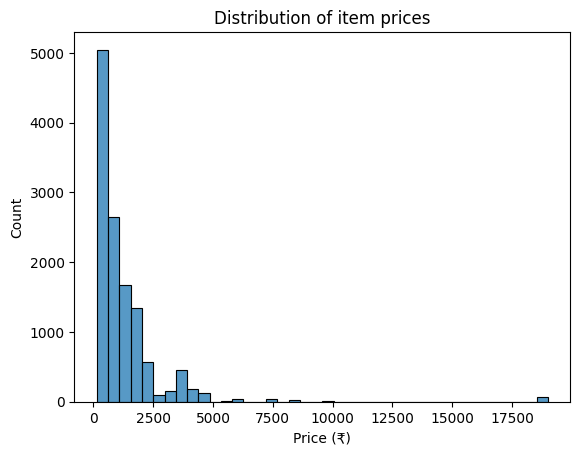

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df["price"], bins=40)
plt.xlabel("Price (₹)")
plt.title("Distribution of item prices")
plt.show()


In [57]:
print("mean:", round(df["price"].mean(), 2))
print("median:", df["price"].median())
print("skew:", round(df["price"].skew(), 2))

mean: 1274.49
median: 776.0
skew: 6.44


In [58]:
num_cols =["price","quantity","revenue","rating"]
print(df[num_cols].corr().round(2))

          price  quantity  revenue  rating
price      1.00     -0.21     0.90    0.09
quantity  -0.21      1.00     0.07   -0.02
revenue    0.90      0.07     1.00    0.08
rating     0.09     -0.02     0.08    1.00


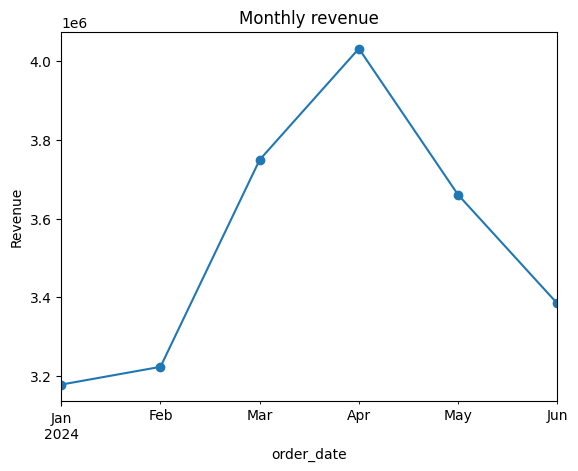

In [59]:
monthly_chart = (df.set_index("order_date").resample("ME")["revenue"].sum())
monthly_chart.plot(marker="o")
plt.ylabel("Revenue")
plt.title("Monthly revenue")
plt.show()


In [60]:
print(monthly_chart)

order_date
2024-01-31    3177822.0
2024-02-29    3222982.0
2024-03-31    3749760.0
2024-04-30    4032618.0
2024-05-31    3660712.0
2024-06-30    3384271.0
Freq: ME, Name: revenue, dtype: float64


In [61]:
df["signup_month"] = df["signup_date"].dt.to_period("M")
cohort = df.groupby("signup_month")["revenue"].mean().round(0)
cohort.tail(4)

,revenue
signup_month,
2024-02,2029.0
2024-03,1799.0
2024-04,1374.0
2024-05,1449.0


In [62]:
# RFM calculation for Feature engineering
#Take a snapshot of the day after the last order is placed

snapshot= order["order_date"].max() + pd.Timedelta(days=1)


rfm = order.groupby("customer_id").agg(r = ("order_date", lambda x: (snapshot - x.max()).days),
                                        f = ("order_id", "nunique"),
                                        m = ("revenue", "sum")).reset_index()
print(rfm.head())


  customer_id   r   f        m
0     CUST001   4   3   1893.0
1     CUST002   5  12  19561.0
2     CUST003   7   8  22474.0
3     CUST004  90   2   4373.0
4     CUST006  37   5  17170.0


In [66]:
# add few more features

rfm = rfm.merge(customer[["customer_id","signup_date","segment","city"]],on = "customer_id", how = "left")
rfm["avg_order_value"] = rfm["m"] / rfm["f"]
rfm["tenure"] = (snapshot - rfm["signup_date"]).dt.days
feat = rfm[["customer_id", "r", "f", "m",
            "avg_order_value", "tenure", "segment", "city"]]
feat.head()

,customer_id,r,f,m,avg_order_value,tenure,segment,city
0,CUST001,4,3,1893.0,631.000000,344,Regular,Hyderabad
1,CUST002,5,12,19561.0,1630.083333,726,Regular,Delhi
2,CUST003,7,8,22474.0,2809.250000,640,Regular,Ahmedabad
3,CUST004,90,2,4373.0,2186.500000,654,NaN,Mumbai
4,CUST006,37,5,17170.0,3434.000000,300,Regular,Chennai
